# Doom Health Gathering: H+Delta trajectory overfit

Adapted from the supplied [Health Gathering H+Delta gist](https://gist.github.com/timka-byzov/3cc4a875991b897eec6131b14869b49e) at `a9488564436610d5e95b6ba0450113d86f968e2d`. H is consolidated KV history; Delta is recent KV history. Descriptor, thinker and actor run with the gist's checkpoint/prefix/tail visibility.

The criterion is **closed-loop free-running reproduction**: the student chooses its own actions, real ViZDoom executes them, and newly rendered frames return to the student. Only training replay uses the saved teacher inputs. A scripted CPU environment check is explicitly labeled as such and is never accepted as teacher data.

## A. Setup and GPU availability

Run on caradhras with this worktree's `.venv/bin/python`. Dependencies for ViZDoom live in the experiment's separate `../deps` folder. Choose a **new RUN** to repeat actual training; existing artifacts are explicitly reused.

Shared use is enabled explicitly with `DOOM_ALLOW_SHARED_GPU=1`. Each stage requires at least 48 GiB free (32 GiB allocator budget plus 16 GiB reserve), or an otherwise idle GPU. Native inference uses a fixed small KV allocation; after engine construction our PyTorch allocator is capped at 32 GiB. With insufficient headroom the notebook displays `NOT RUN`. Restart the kernel after changing GPU visibility.

In [1]:
import os
import sys
from pathlib import Path

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "python/minisgl/training/recording.py").exists()
)
os.chdir(ROOT)
DEPS = ROOT.parent / "deps"
sys.path[:0] = [str(ROOT / "python"), str(ROOT / "scripts"), str(DEPS)]
os.environ["PYTHONPATH"] = ":".join([str(ROOT / "python"), str(ROOT / "scripts"), str(DEPS)])
os.environ["PATH"] = str(Path(sys.executable).parent) + ":/usr/local/cuda/bin:" + os.environ["PATH"]
os.environ.setdefault("CUDA_HOME", "/usr/local/cuda")
os.environ.update(
    SDL_VIDEODRIVER="dummy",
    SDL_AUDIODRIVER="dummy",
    MPLBACKEND="Agg",
    OMP_NUM_THREADS="4",
    MKL_NUM_THREADS="4",
)

from minisgl_examples.training.doom_health.gpu import gpu_state

os.environ.setdefault("DOOM_ALLOW_SHARED_GPU", "1")
os.environ.setdefault("DOOM_GPU_LIMIT_GIB", "32")
GPUS = gpu_state()
requested_gpu = os.environ.get("CUDA_VISIBLE_DEVICES")
free = [
    g
    for g in GPUS
    if g["available"] and (requested_gpu is None or requested_gpu in (str(g["index"]), g["uuid"]))
]
RUN_GPU = bool(free)
os.environ["CUDA_VISIBLE_DEVICES"] = str(free[0]["index"]) if free else ""

import json
from io import BytesIO

import matplotlib.pyplot as plt
from IPython.display import Image as DisplayImage
from IPython.display import Markdown, display
from PIL import Image

from minisgl_examples.training.doom_health import experiment as exp
from minisgl_examples.training.doom_health.environment import Setup
from minisgl_examples.training.doom_health.preflight import check as check_cpu
from minisgl_examples.training.process import isolated

TEACHER = "Qwen/Qwen3.5-4B"
STUDENT = "Qwen/Qwen3.5-0.8B"
SETUP = exp.asdict(Setup())
RUN = ROOT / "training_runs/doom_health"
RUN.mkdir(parents=True, exist_ok=True)
print(json.dumps(GPUS, indent=2))
print("GPU stages enabled:", RUN_GPU, "Run:", RUN)
print(SETUP)


def display_figure(fig):
    with BytesIO() as buffer:
        fig.savefig(buffer, format="png", dpi=150, bbox_inches="tight")
        display(DisplayImage(data=buffer.getvalue()))


def stage(path, function, *args, **kwargs):
    path = Path(path)
    if path.exists():
        print("Saved artifact:", path)
        return exp.load(path)
    if not RUN_GPU:
        print("NOT RUN — insufficient GPU headroom:", path.name)
        return None
    isolated(function, *args, **kwargs)
    return exp.load(path)

[
  {
    "index": 0,
    "uuid": "GPU-217bd8f1-3f36-8e20-497e-05a1ea1f4666",
    "memory_mib": 52731,
    "free_mib": 28349,
    "total_mib": 81559,
    "utilization": 50,
    "pids": [
      3985224,
      22468
    ],
    "available": false
  },
  {
    "index": 1,
    "uuid": "GPU-6d0634a0-1665-612a-db32-7acd17eddb11",
    "memory_mib": 13843,
    "free_mib": 67237,
    "total_mib": 81559,
    "utilization": 23,
    "pids": [
      3956682
    ],
    "available": true
  }
]
GPU stages enabled: True Run: /home/mrozaeva/experiments/doom-health-overfit/repo/training_runs/doom_health
{'seed': 105, 'agent_seed': 7, 'max_actions': 12, 'min_actions': 4, 'frame_skip': 4, 'episode_timeout': 16000, 'consolidation_steps': 3, 'readiness_interval': 14, 'thought_length': 50, 'description_length': 8, 'history_token_limit': 4096, 'max_pixels': 65536, 'kv_tokens': 16384, 'max_seq_len': 8192, 'prefill_rows': 128, 'dtype': 'float16'}


## B. Actual environment and input preparation

Use the gist's seed 105, action mapping `wait/forward/right/left`, frame skip 4 and Health Gathering scenario. The short diagnostic stops after a real health increase and at least four actions, or at the 12-action cap. Delta is consolidated every three actions, so the same trace exercises append, clear and a subsequent read from H. This is not a claim to solve the entire 16,000-tick survival scenario.

The CPU preflight runs two independent real environments with the same scripted actions and verifies identical frames/state. It also checks the actual Qwen processor, one-token action IDs, two-image inputs and three-axis MRoPE layout. No LLM weights or teacher actions are involved.

CPU checks: cpu_processor_preflight deterministic: True
Action IDs: {'continue': [9252], 'wait': [11158], 'forward': [13048], 'right': [1246], 'left': [2282]}
Tensor shapes: {'input_ids': [1, 116], 'attention_mask': [1, 116], 'mm_token_type_ids': [1, 116], 'pixel_values': [432, 1536], 'image_grid_thw': [2, 3]} MRoPE: [3, 116]


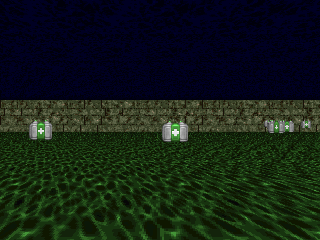

In [2]:
cpu_path = RUN / "cpu_preflight/inputs.json"
if not cpu_path.exists():
    isolated(check_cpu, RUN / "cpu_preflight", SETUP, log_path=RUN / "cpu_inputs.log")
cpu = exp.load(cpu_path)
assert cpu["kind"] == "cpu_processor_preflight" and not cpu["teacher_inference"]
assert cpu["environment"]["deterministic"]
print("CPU checks:", cpu["kind"], "deterministic:", cpu["environment"]["deterministic"])
print("Action IDs:", cpu["action_ids"])
print("Tensor shapes:", cpu["tensor_shapes"], "MRoPE:", cpu["mrope_shape"])
display(DisplayImage(filename=str(RUN / "cpu_preflight/initial.png")))

## C. Teacher collection through real AsyncLLM

The teacher controls a live environment. Descriptor/thinker seed and decode requests run concurrently. At a checkpoint they write into separate new tail blocks while actor probes the already-published prefixes. `continue` publishes tails with `append_block`; a real action calls `env.step`. Every role completes the round barrier before blocks are freed.

The agent uses the supplied prompts with one factual correction: game time advances at `env.step`, not during model reasoning. All token selection is greedy for reproducibility. Emitted descriptor/thinker tokens and actor decisions are labeled at their actual producing rows; unused lookahead predictions stay masked.

A successful teacher must recover health, remain alive and use history after an H+Delta consolidation. A positive living reward alone does not qualify.

In [3]:
teacher_path = RUN / "teacher.json"
teacher = stage(
    teacher_path, exp.collect, TEACHER, teacher_path, SETUP, log_path=RUN / "teacher.log"
)
if teacher is not None:
    exp.assert_real(teacher)
    assert teacher["model"] == TEACHER and teacher["setup"] == SETUP
    print(teacher["assessment"])
    for row in teacher["steps"]:
        print(
            row["step"],
            row["action"],
            row["health_before"],
            "→",
            row["health_after"],
            "probes",
            len(row["probes"]),
            "append Δ→H",
            row["consolidated"],
        )
    assert teacher["assessment"]["goal_achieved"], (
        "Teacher failed: try a stronger teacher/another seed before training."
    )

Saved artifact: /home/mrozaeva/experiments/doom-health-overfit/repo/training_runs/doom_health/teacher.json


{'health_recoveries': 1, 'alive': True, 'consolidations': 2, 'consolidated_h_read': True, 'goal_achieved': True, 'actions': 7, 'return': 28.0, 'final_health': 100.0}
1 forward 92.0 → 92.0 probes 1 append Δ→H False
2 forward 92.0 → 92.0 probes 1 append Δ→H False
3 forward 92.0 → 92.0 probes 1 append Δ→H True
4 forward 92.0 → 92.0 probes 1 append Δ→H False
5 forward 92.0 → 92.0 probes 1 append Δ→H False
6 forward 92.0 → 92.0 probes 1 append Δ→H True
7 forward 92.0 → 100.0 probes 1 append Δ→H False


## D. Rollout inspection

Inspect actual live observations, descriptions, thoughts, actor probabilities, action outcomes and consolidation events. The trace retains pixels/grids/types/MRoPE, request order, cache-view lengths and append/clear references. No detached numerical KV dump is substituted for differentiable replay.

Generated summaries are re-prefilled into Delta as application inputs. During student evaluation they are rebuilt from the student's own outputs, never taken from teacher text.

/home/mrozaeva/experiments/doom-health-overfit/repo/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{
  "rows": 3396,
  "targets": 114,
  "image_requests": 7,
  "decode_batch_sizes": [
    2,
    2,
    2,
    2,
    2,
    2,
    2,
    2,
    1,
    2,
    2,
    2,
    2,
    2,
    2,
    1,
    1,
    1,
    2,
    2,
    2,
    2,
    2,
    2,
    1,
    1,
    1,
    2,
    2,
    2,
    2,
    2,
    2,
    1,
    1,
    1,
    2,
    2,
    2,
    2,
    2,
    2,
    1,
    1,
    1,
    2,
    2,
    2,
    2,
    2,
    2,
    1,
    1,
    1,
    2,
    2,
    2,
    2,
    2,
    2,
    1,
    1,
    1
  ],
  "append_operations": 2,
  "clear_operations": 61,
  "events": [
    {
      "event": "observation",
      "step": 1,
      "trace_step": 3,
      "trace_rows": 372,
      "blocks": [
        {
          "id": 0,
          "tokens": 242,
          "mrope_span": 242
        },
        {
          "id": 1,
          "tokens": 14,
          "mrope_span": 14
        },
        {
          "id": 2,
          "tokens": 116,
          "mrope_span": 26
        },
        {

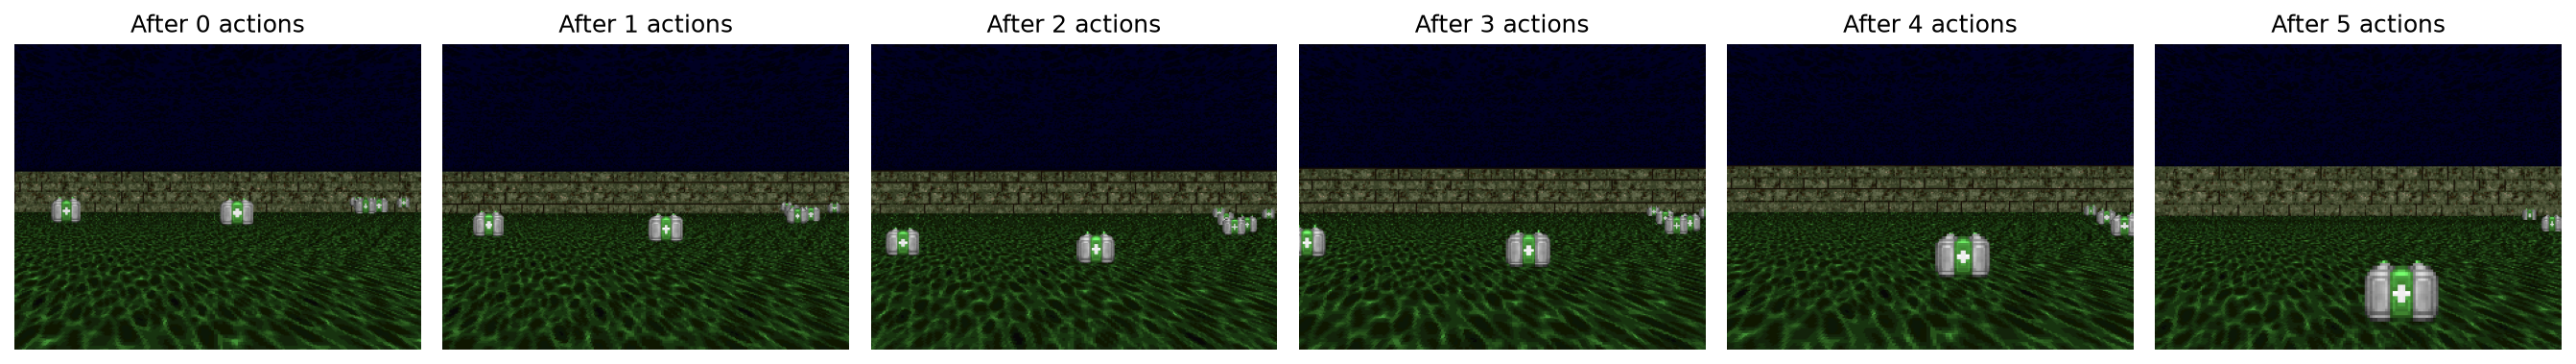

In [4]:
if teacher is not None:
    inspection = exp.inspect_rollout(teacher_path)
    print(json.dumps(inspection, indent=2))
    for row in teacher["steps"]:
        print(f"Step {row['step']}: {row['action']}")
        print("Descriptor:", row["description"])
        print("Thinker:", row["thought"])
        print("Actor probes:", row["probes"])
    count = min(len(teacher["steps"]) + 1, 6)
    fig, axes = plt.subplots(1, count, figsize=(3 * count, 2.5), squeeze=False)
    for i, ax in enumerate(axes[0]):
        ax.imshow(Image.open(teacher_path.with_suffix("") / f"frames/{i:03d}.png"))
        ax.set_title(f"After {i} actions")
        ax.axis("off")
    plt.tight_layout()
    display_figure(fig)
    plt.close(fig)
else:
    print("NOT RUN — no real teacher rollout yet.")

## E. Same-weight differentiable replay checks

Use the public `RecordedAsyncLLM` / `Trace` / `replay_trace` API. Full attention and GDN reconstruct actual cache visibility, including copies from Delta to H and asynchronous role-tail publication. Pixels are re-encoded on the current weights. Loss targets apply only to model-emitted rows; image/user/summary/unused-lookahead rows use -100.

Compare teacher inference with the same teacher weights, and the baseline student's own trajectory with the same student weights. Maximum absolute raw target-logprob error must be ≤0.1. The actor's constrained choice probabilities and the raw model logprobs are reported separately.

In [5]:
teacher_parity = None
if teacher is not None:
    parity_path = RUN / "teacher_parity.json"
    teacher_parity = stage(
        parity_path,
        exp.check_replay,
        teacher_path,
        parity_path,
        dtype="float16",
        log_path=RUN / "teacher_parity.log",
    )
    if teacher_parity is not None:
        print(teacher_parity["parity"])
        assert teacher_parity["parity"]["passed"]
before_path = RUN / "student_before.json"
before = stage(
    before_path, exp.collect, STUDENT, before_path, SETUP, log_path=RUN / "student_before.log"
)
if before is not None:
    assert before["setup"] == SETUP and before["model"] == STUDENT
    print("Before:", before["assessment"])

Saved artifact: /home/mrozaeva/experiments/doom-health-overfit/repo/training_runs/doom_health/teacher_parity.json
{'max_abs_logprob_error': 0.05234265327453613, 'mean_abs_logprob_error': 0.006594925435165989, 'by_phase': {'step_1/descriptor': {'count': 8, 'max_abs': 0.04667031764984131}, 'step_1/thinker': {'count': 9, 'max_abs': 0.042508840560913086}, 'step_1/actor': {'count': 1, 'max_abs': 1.701340079307556e-05}, 'step_2/descriptor': {'count': 6, 'max_abs': 0.03067314624786377}, 'step_2/thinker': {'count': 9, 'max_abs': 0.0076187849044799805}, 'step_2/actor': {'count': 1, 'max_abs': 0.005610644817352295}, 'step_3/descriptor': {'count': 6, 'max_abs': 0.02246832847595215}, 'step_3/thinker': {'count': 9, 'max_abs': 0.006665810942649841}, 'step_3/actor': {'count': 1, 'max_abs': 0.0034563839435577393}, 'step_4/descriptor': {'count': 6, 'max_abs': 0.048541128635406494}, 'step_4/thinker': {'count': 9, 'max_abs': 0.05234265327453613}, 'step_4/actor': {'count': 1, 'max_abs': 0.0056274533271789

Before: {'health_recoveries': 0, 'alive': True, 'consolidations': 4, 'consolidated_h_read': True, 'goal_achieved': False, 'actions': 12, 'return': 48.0, 'final_health': 84.0}


## F. Overfit one trajectory

Reuse the existing `training.student.train_student` workflow with FP32 weights, AdamW LR 3e-6, gradient clipping, chunked loss and at most 80 updates. It updates model parameters, saves the HF checkpoint and checks reloaded logits. An additional q_proj comparison casts both base and trained tensors to FP32 before measuring parameter delta, so dtype conversion is not counted as an update.

Training is gated on real teacher success and both replay checks. Stub/CPU-preflight data is explicitly rejected.

In [6]:
training = None
if teacher_parity is not None and before is not None:
    training_path = RUN / "trained/training.json"
    training = stage(
        training_path,
        exp.train,
        teacher_path,
        STUDENT,
        before_path,
        RUN / "trained",
        steps=80,
        lr=3e-6,
        log_path=RUN / "training.log",
    )
    if training is not None:
        print("Loss:", training["initial"]["loss"], "→", training["final"]["loss"])
        print("Updates:", training["completed_steps"], "Reload exact:", training["reload_exact"])
        print("Parameter update:", training["parameter_update"])
        assert training["parameter_update"]["max_abs_delta"] > 0
else:
    print("NOT RUN — real teacher/baseline/replay prerequisites are missing.")

Saved artifact: /home/mrozaeva/experiments/doom-health-overfit/repo/training_runs/doom_health/trained/training.json
Loss: 1.1017812490463257 → 0.000436093017924577
Updates: 5 Reload exact: True
Parameter update: {'parameter': 'model.language_model.layers.11.self_attn.q_proj.weight', 'max_abs_delta': 1.506507396697998e-05, 'before_f32_sha256': '17345fbbeed1813d3d0f7c9c4667d1642e7f3d88932b152a5465eabd3152bfd0', 'after_f32_sha256': 'b586459c0275b8755dcb49a7d633e7eca30d55763c66126cd6a20dc83252d754'}


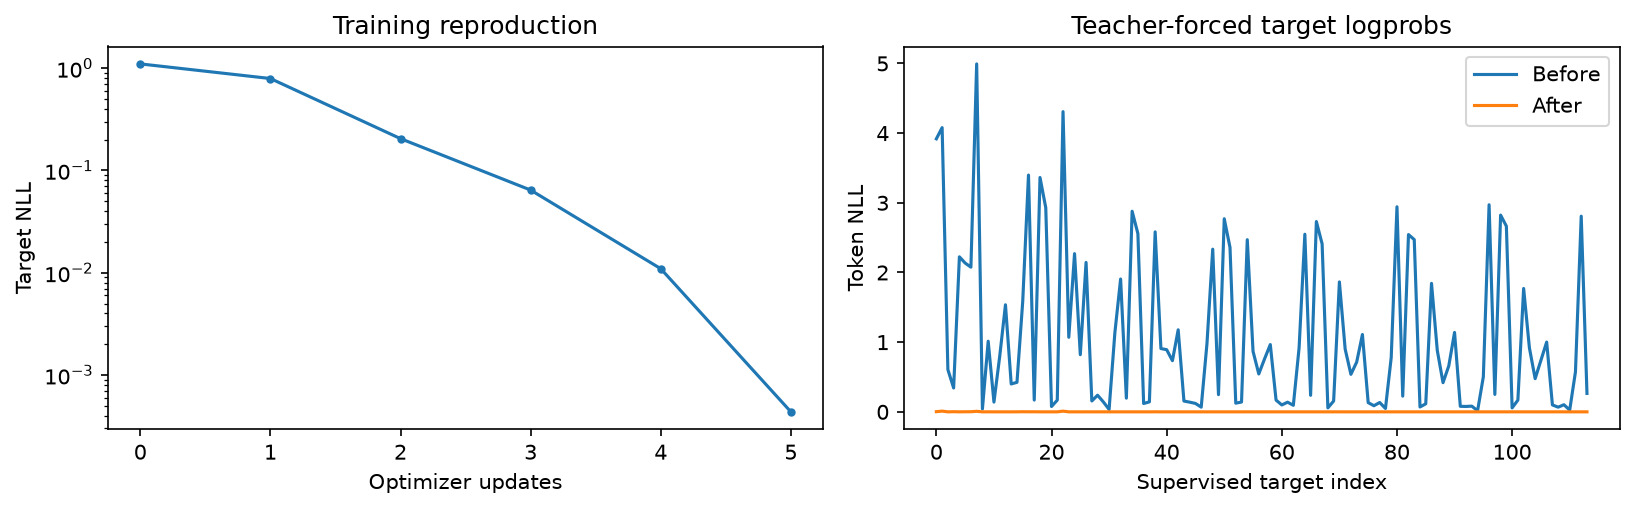

In [7]:
if training is not None:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(
        range(len(training["losses"]) + 1),
        training["losses"] + [training["final"]["loss"]],
        marker=".",
    )
    axes[0].set(
        xlabel="Optimizer updates", ylabel="Target NLL", title="Training reproduction", yscale="log"
    )
    axes[1].plot(training["initial"]["examples"][0]["nll"], label="Before")
    axes[1].plot(training["final"]["examples"][0]["nll"], label="After")
    axes[1].set(
        xlabel="Supervised target index", ylabel="Token NLL", title="Teacher-forced target logprobs"
    )
    axes[1].legend()
    plt.tight_layout()
    fig.savefig(RUN / "training_loss.png", dpi=160)
    display_figure(fig)
    plt.close(fig)
else:
    print("NOT RUN — there is no real training loss to plot.")

## G. Reloaded student in a fresh live game

Same environment seed, frame skip, prompts, action policy and checkpoint rules. The trained student chooses its own tokens and actions. ViZDoom executes those actions and returns newly rendered observations; no teacher actions, screenshots or summaries enter this run. Teacher-forced fit and free-running reproduction are scored separately.

In [8]:
after = None
if training is not None:
    checkpoint = RUN / "trained/checkpoint"
    reload_path = RUN / "checkpoint_reload.json"
    reloaded = stage(
        reload_path,
        exp.verify,
        teacher_path,
        checkpoint,
        RUN / "trained/training.json",
        reload_path,
        log_path=RUN / "checkpoint_reload.log",
    )
    if reloaded is not None:
        assert reloaded["passed"]
    after_path = RUN / "student_after.json"
    after = stage(
        after_path, exp.collect, checkpoint, after_path, SETUP, log_path=RUN / "student_after.log"
    )
    if after is not None:
        print("After:", after["assessment"])
else:
    print("NOT RUN — no trained student checkpoint.")

Saved artifact: /home/mrozaeva/experiments/doom-health-overfit/repo/training_runs/doom_health/checkpoint_reload.json
Saved artifact: /home/mrozaeva/experiments/doom-health-overfit/repo/training_runs/doom_health/student_after.json


After: {'health_recoveries': 1, 'alive': True, 'consolidations': 2, 'consolidated_h_read': True, 'goal_achieved': True, 'actions': 7, 'return': 28.0, 'final_health': 100.0}


{
  "teacher": {
    "health_recoveries": 1,
    "alive": true,
    "consolidations": 2,
    "consolidated_h_read": true,
    "goal_achieved": true,
    "actions": 7,
    "return": 28.0,
    "final_health": 100.0
  },
  "runs": {
    "before": {
      "assessment": {
        "health_recoveries": 0,
        "alive": true,
        "consolidations": 4,
        "consolidated_h_read": true,
        "goal_achieved": false,
        "actions": 12,
        "return": 48.0,
        "final_health": 84.0
      },
      "roles": {
        "descriptor": {
          "exact": false,
          "teacher_tokens": 44,
          "student_tokens": 96,
          "sequence_similarity": 0.2
        },
        "thinker": {
          "exact": false,
          "teacher_tokens": 63,
          "student_tokens": 108,
          "sequence_similarity": 0.32748538011695905
        },
        "actor": {
          "exact": false,
          "teacher_tokens": 7,
          "student_tokens": 12,
          "sequence_similarity"

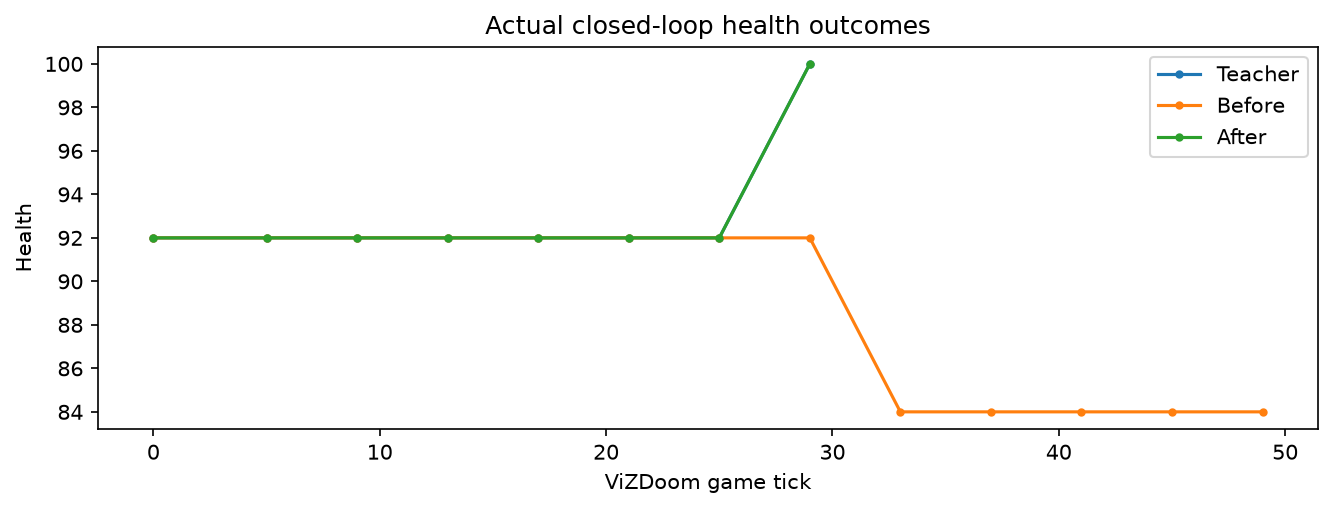

In [9]:
comparison = None
if teacher is not None and before is not None and after is not None:
    comparison_path = RUN / "comparison.json"
    comparison = (
        exp.load(comparison_path)
        if comparison_path.exists()
        else exp.compare(teacher_path, before_path, after_path, comparison_path)
    )
    print(json.dumps(comparison, indent=2))
    fig, ax = plt.subplots(figsize=(9, 3.5))
    for label, data in [("Teacher", teacher), ("Before", before), ("After", after)]:
        ax.plot(
            [0] + [s["game_tick"] for s in data["steps"]],
            [data["initial_state"]["health"]] + [s["health_after"] for s in data["steps"]],
            marker=".",
            label=label,
        )
    ax.set(xlabel="ViZDoom game tick", ylabel="Health", title="Actual closed-loop health outcomes")
    ax.legend()
    plt.tight_layout()
    fig.savefig(RUN / "health_outcomes.png", dpi=160)
    display_figure(fig)
    plt.close(fig)
else:
    print("NOT RUN — before/after live-game comparison is incomplete.")

The comparison checks exact environment actions, post-action frame hashes, health and game ticks, all role-token streams and checkpoint/consolidation schedule. A low replay loss or positive living reward alone never establishes success.

This is a short same-seed overfit diagnostic. Long-horizon survival, unseen seeds and the colleague's 64k/27B collection are not reproduced by this small test. No My Way Home code is used. Every skipped GPU stage stays explicitly unverified.

### Visual-input control

Repeat the trained student in the same live game, replacing both model input frames with black images. Environment physics and student-driven actions remain real. This intervention checks sensitivity to visual input; it does not establish generalization to unseen games. Report any unchanged behavior explicitly.

In [10]:
visual_control = None
if training is not None:
    control_path = RUN / "student_blank.json"
    visual_control = stage(
        control_path,
        exp.collect,
        RUN / "trained/checkpoint",
        control_path,
        SETUP,
        control="blank",
        log_path=RUN / "student_blank.log",
    )
    if visual_control is not None and after is not None:
        assert visual_control["control"] == "blank"
        assert visual_control["setup"] == after["setup"]
        assert visual_control["initial_state"] == after["initial_state"]
        print("Black-frame control:", visual_control["assessment"])
        print("Actions:", [s["action"] for s in visual_control["steps"]])
        for role in ("descriptor", "thinker", "actor"):

            def tokens(d):
                return [
                    s["token"]
                    for s in sorted(d["samples"], key=lambda s: s["emission"])
                    if s["role"] == role
                ]

            print(role, "tokens unchanged:", tokens(visual_control) == tokens(after))
        unchanged = all(
            [
                s["token"]
                for s in sorted(visual_control["samples"], key=lambda s: s["emission"])
                if s["role"] == role
            ]
            == [
                s["token"]
                for s in sorted(after["samples"], key=lambda s: s["emission"])
                if s["role"] == role
            ]
            for role in ("descriptor", "thinker", "actor")
        )
        if unchanged:
            display(
                Markdown(
                    "**Visual dependence not established:** black images produce identical role-token streams. The student reproduces this memorized short trajectory, but the control does not show that it needs new visual observations."
                )
            )

else:
    print("NOT RUN — no trained checkpoint for visual-input control.")

Saved artifact: /home/mrozaeva/experiments/doom-health-overfit/repo/training_runs/doom_health/student_blank.json


Black-frame control: {'health_recoveries': 1, 'alive': True, 'consolidations': 2, 'consolidated_h_read': True, 'goal_achieved': True, 'actions': 7, 'return': 28.0, 'final_health': 100.0}
Actions: ['forward', 'forward', 'forward', 'forward', 'forward', 'forward', 'forward']
descriptor tokens unchanged: True
thinker tokens unchanged: True
actor tokens unchanged: True


**Visual dependence not established:** black images produce identical role-token streams. The student reproduces this memorized short trajectory, but the control does not show that it needs new visual observations.

In [11]:
status = {
    "cpu_environment_verified": cpu["environment"]["deterministic"],
    "real_teacher_collected": teacher is not None,
    "teacher_replay_verified": teacher_parity is not None,
    "real_student_trained": training is not None,
    "free_running_success": bool(comparison and comparison["free_running_success"]),
    "exact_trajectory": bool(comparison and comparison["exact_trajectory"]),
}
print(json.dumps(status, indent=2))
if not status["free_running_success"]:
    display(
        Markdown(
            "**Experiment not yet successful.** Read the explicit NOT RUN/failed prerequisites above. CPU checks and toy-model gradient tests do not count as real teacher/student overfit."
        )
    )
else:
    display(
        Markdown(
            "**Short closed-loop trajectory reproduction passed.** Exact token reproduction is reported separately. Read the visual-input control above: trajectory reproduction alone does not establish visual dependence."
        )
    )
print("Artifacts:", RUN)

{
  "cpu_environment_verified": true,
  "real_teacher_collected": true,
  "teacher_replay_verified": true,
  "real_student_trained": true,
  "free_running_success": true,
  "exact_trajectory": true
}


**Short closed-loop trajectory reproduction passed.** Exact token reproduction is reported separately. Read the visual-input control above: trajectory reproduction alone does not establish visual dependence.

Artifacts: /home/mrozaeva/experiments/doom-health-overfit/repo/training_runs/doom_health
